# Comment/Suggestion Classifier: Rules vs. scikit-learn

**Goal:** automatically pull comments and suggestions (opinions, concerns, proposed actions, recommendations) out of a meeting transcript, and choose between two free, local approaches **based on measured results**, not a guess.

**Data:** `sample_transcript_otter.txt`, a **fictional** planning meeting written for this demo (41 speaker turns, Otter.ai export format). All people, companies and details are made up, so the outputs are safe to share. The original analysis used a real work meeting, which is not published.

**Approaches compared:**
1. **Rules engine:** regex/keyword patterns (the `--engine rules` option in `extract_meeting_comments.py`)
2. **scikit-learn classifier:** TF-IDF + Logistic Regression, trained and scored with 5-fold cross-validation on hand-labeled sentences from the transcript

A third option, a free local LLM through Ollama, is built into `extract_meeting_comments.py --engine ollama` but is not scored here (see the conclusion).

**Tools:** Python (re, pandas, scikit-learn), openpyxl for the Excel repository

**Related files in this folder:**
- `run_demo.py` runs every tool end to end on the sample meeting
- `extract_meeting_comments.py` extracts comments into an Excel repository with speaker, topic and ID
- `extract_categories.py` tags keyword categories by speaker

**Context:** built during an AI Builder course to automate meeting notes.

## 1. Parse the transcript

This transcript uses Otter.ai's format: `Speaker N  MM:SS` on its own line, then the turn's text. That's different from the simple `Speaker: text` format `extract_meeting_comments.py` expects, so this parser handles the Otter layout (`run_demo.py` converts between the two).

In [1]:
import re
from pathlib import Path

TRANSCRIPT_PATH = Path("sample_transcript_otter.txt")
TURN_HEADER_RE = re.compile(r"^Speaker\s+(\d+)\s+(\d{1,2}:\d{2})\s*$")

def parse_otter_transcript(raw_text: str):
    """Parse an Otter.ai-style transcript into a list of (speaker, text) turns."""
    lines = raw_text.splitlines()
    turns = []
    current_speaker = None
    current_text_lines = []

    for line in lines:
        stripped = line.strip()
        match = TURN_HEADER_RE.match(stripped)
        if match:
            if current_speaker is not None:
                turns.append((current_speaker, " ".join(current_text_lines).strip()))
            current_speaker = f"Speaker {match.group(1)}"
            current_text_lines = []
        elif stripped and not stripped.lower().startswith("transcribed by"):
            current_text_lines.append(stripped)

    if current_speaker is not None:
        turns.append((current_speaker, " ".join(current_text_lines).strip()))

    return [t for t in turns if t[1]]

raw_text = TRANSCRIPT_PATH.read_text(encoding="utf-8")
turns = parse_otter_transcript(raw_text)
print(f"Parsed {len(turns)} speaker turns from the sample transcript.")
turns[:3]


Parsed 41 speaker turns from the sample transcript.


[('Speaker 1', 'Good morning, everyone. Can you all hear me okay?'),
 ('Speaker 2', 'Yes, loud and clear.'),
 ('Speaker 3', 'Morning. I can hear you.')]

## 2. Ground-truth evaluation set

To measure which approach works better, each sentence below was hand-labeled: 1 if it's a comment/suggestion (an opinion, concern, proposed action, or recommendation), 0 if it isn't (backchannel, greetings, plain factual answers, info-seeking questions).

The set deliberately includes hard cases for both engines: suggestions with no trigger phrase ("Start with rules.", "Thirty days seems short..."), and non-suggestions that contain a trigger phrase ("Let's talk timeline.", "I think so too."). It is small and written for the demo, so the scores show how the comparison works, not how either engine would do on real meetings.

In [2]:
labeled_examples = [
    # --- comments / suggestions (label = 1) ---
    ("Speaker 2", "I think we should start with a small set of requirements for the MVP.", 1),
    ("Speaker 3", "I'm concerned about the cost if we leave the AWS host running all month.", 1),
    ("Speaker 3", "It might be better to shut it down on weekends.", 1),
    ("Speaker 1", "What if we set a monthly budget cap and get an alert when we hit 80 percent of it?", 1),
    ("Speaker 4", "Could we email them a one-page summary every Monday?", 1),
    ("Speaker 2", "We need to fix the matching logic before we load it into the CRM.", 1),
    ("Speaker 3", "I can write a Python script to remove the duplicates.", 1),
    ("Speaker 1", "Sam owns the cleanup and Jordan reviews it.", 1),
    ("Speaker 4", "Honestly, that feels light.", 1),
    ("Speaker 4", "You may want more capacity on the team once the store data starts coming in.", 1),
    ("Speaker 1", "Maybe we can borrow someone from the reporting team in month two.", 1),
    ("Speaker 2", "I'd suggest we also define what churn means for a loyalty member.", 1),
    ("Speaker 2", "My proposal is no visits for 30 days.", 1),
    ("Speaker 3", "Thirty days seems short for people who only shop once a month.", 1),
    ("Speaker 3", "I recommend we keep the scoring model separate from the app, so we can update it without a new release of the platform.", 1),
    ("Speaker 2", "Start with rules.", 1),
    ("Speaker 2", "We can test machine learning once we have a few months of data and real insights about what members redeem.", 1),
    ("Speaker 2", "It would be good to have a dry run the week before, just to catch any bugs in the weekly report.", 1),
    ("Speaker 4", "Our consulting partner charges by the hour, so let's keep the scope tight and avoid change requests after launch.", 1),
    ("Speaker 2", "How about we put the open questions in a shared tracker tool so nothing gets lost?", 1),

    # --- not comments / suggestions (label = 0) ---
    ("Speaker 1", "Good morning, everyone.", 0),
    ("Speaker 1", "Can you all hear me okay?", 0),
    ("Speaker 2", "Yes, loud and clear.", 0),
    ("Speaker 4", "Hi all, thanks for having me.", 0),
    ("Speaker 3", "The AWS host is up and running.", 0),
    ("Speaker 1", "Perfect, thanks Sam.", 0),
    ("Speaker 4", "What does the pilot actually cover?", 0),
    ("Speaker 1", "It covers about 2,000 loyalty members at three stores.", 0),
    ("Speaker 4", "That makes sense to me.", 0),
    ("Speaker 2", "Yeah.", 0),
    ("Speaker 1", "Sure, we can do that.", 0),
    ("Speaker 4", "How many people do you have on this right now?", 0),
    ("Speaker 1", "Three of us, about half time each.", 0),
    ("Speaker 4", "Is the app the same for every store?", 0),
    ("Speaker 1", "Yes, same app, same offers.", 0),
    ("Speaker 1", "Let's talk timeline.", 0),
    ("Speaker 3", "That's tight but doable.", 0),
    ("Speaker 4", "Sounds good.", 0),
    ("Speaker 1", "Understood.", 0),
    ("Speaker 1", "I think so too.", 0),
]

print(f"{len(labeled_examples)} labeled sentences "
      f"({sum(l for _, _, l in labeled_examples)} positive / "
      f"{sum(1 - l for _, _, l in labeled_examples)} negative)")

40 labeled sentences (20 positive / 20 negative)


## 3. Engine 1: rules engine (regex/keyword patterns)

Same patterns as `extract_meeting_comments.py --engine rules`.

In [3]:
SUGGESTION_PATTERNS = [
    r"\bi (?:think|suggest|recommend|propose)\b",
    r"\bwe should\b",
    r"\byou should\b",
    r"\blet'?s\b",
    r"\bwhat if we\b",
    r"\bhow about\b",
    r"\bit (?:would|might) be (?:good|better|worth|nice)\b",
    r"\bmaybe we\b",
    r"\bconsider(?:ing)?\b",
    r"\bworth (?:considering|trying|exploring)\b",
    r"\bi'?m (?:concerned|worried)\b",
    r"\b(?:concern|issue|problem) (?:is|with)\b",
    r"\bwe need to\b",
    r"\brecommend(?:ation|ing)?\b",
    r"\bpropos(?:e|al|ing)\b",
    r"\bcould we\b",
    r"\bshould we\b",
    r"\bi'?d (?:suggest|recommend|propose)\b",
]
SUGGESTION_REGEX = re.compile("|".join(SUGGESTION_PATTERNS), re.IGNORECASE)

def rules_predict(text: str) -> int:
    return 1 if SUGGESTION_REGEX.search(text) else 0

rules_preds = [rules_predict(text) for _, text, _ in labeled_examples]
true_labels = [label for _, _, label in labeled_examples]


## 4. Engine 2: scikit-learn (TF-IDF + Logistic Regression)

With only 40 labeled examples, a single train/test split would be too noisy to trust, so this uses 5-fold **stratified cross-validation**: the model is trained and tested 5 times on different splits, and results are averaged.

In [4]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict

texts = [text for _, text, _ in labeled_examples]
labels = np.array([label for _, _, label in labeled_examples])

sklearn_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, stop_words="english")),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sklearn_preds = cross_val_predict(sklearn_pipeline, texts, labels, cv=cv)


## 5. Compare the two on the same sentences

In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import pandas as pd

def score(name, preds):
    return {
        "Engine": name,
        "Accuracy": round(accuracy_score(true_labels, preds), 2),
        "Precision": round(precision_score(true_labels, preds, zero_division=0), 2),
        "Recall": round(recall_score(true_labels, preds, zero_division=0), 2),
        "F1": round(f1_score(true_labels, preds, zero_division=0), 2),
    }

results = pd.DataFrame([
    score("Rules engine (regex)", rules_preds),
    score("scikit-learn (TF-IDF + LogReg, 5-fold CV)", sklearn_preds),
])
results


,Engine,Accuracy,Precision,Recall,F1
0,Rules engine (regex),0.78,0.87,0.65,0.74
1,"scikit-learn (TF-IDF + LogReg, 5-fold CV)",0.42,0.43,0.50,0.47


### Where they disagreed with the true label

Worth reading these directly, this is more informative than the summary metrics given how small the sample is.

In [6]:
mismatches = []
for (speaker, text, true_label), rule_pred, sk_pred in zip(labeled_examples, rules_preds, sklearn_preds):
    if rule_pred != true_label or sk_pred != true_label:
        mismatches.append({
            "speaker": speaker,
            "text": text[:90],
            "true": true_label,
            "rules_pred": rule_pred,
            "sklearn_pred": sk_pred,
        })

pd.DataFrame(mismatches)


,speaker,text,true,rules_pred,sklearn_pred
0,Speaker 3,I'm concerned about the cost if we leave the A...,1,1,0
1,Speaker 4,Could we email them a one-page summary every M...,1,1,0
2,Speaker 3,I can write a Python script to remove the dupl...,1,0,0
3,Speaker 1,Sam owns the cleanup and Jordan reviews it.,1,0,0
4,Speaker 4,"Honestly, that feels light.",1,0,0
5,Speaker 4,You may want more capacity on the team once th...,1,0,0
6,Speaker 2,I'd suggest we also define what churn means fo...,1,1,0
7,Speaker 3,Thirty days seems short for people who only sh...,1,0,1
8,Speaker 3,I recommend we keep the scoring model separate...,1,1,0
9,Speaker 2,Start with rules.,1,0,1


## 6. Which one actually won on this run?

Computed directly from the `results` table above, not asserted, this will reflect whatever the real numbers came out to.

In [7]:
winner_row = results.loc[results["F1"].idxmax()]
loser_row = results.loc[results["F1"].idxmin()]

if winner_row["F1"] == loser_row["F1"]:
    print(f"Tied on F1 at {winner_row['F1']}.")
else:
    print(f"On this {len(labeled_examples)}-sentence sample, \"{winner_row['Engine']}\" scored higher "
          f"(F1 {winner_row['F1']} vs {loser_row['F1']}).")

print()
print(results.to_string(index=False))


On this 40-sentence sample, "Rules engine (regex)" scored higher (F1 0.74 vs 0.47).

                                   Engine  Accuracy  Precision  Recall   F1
                     Rules engine (regex)      0.78       0.87    0.65 0.74
scikit-learn (TF-IDF + LogReg, 5-fold CV)      0.42       0.43    0.50 0.47


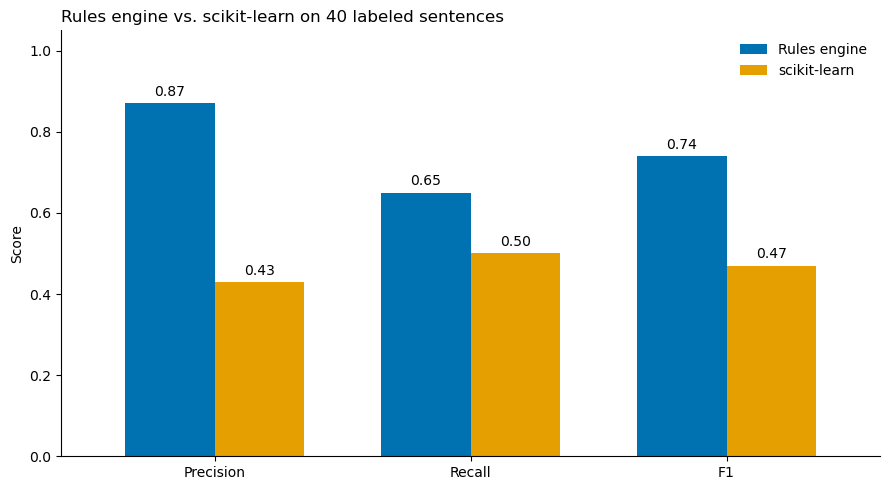

In [8]:
# summary chart: precision, recall and F1 for each engine
import matplotlib.pyplot as plt
chart = results.set_index('Engine')[['Precision', 'Recall', 'F1']]
chart.index = ['Rules engine', 'scikit-learn']
ax = chart.T.plot(kind='bar', figsize=(9, 5), color=['#0072B2', '#E69F00'], rot=0, width=0.7)
for c in ax.containers:
    ax.bar_label(c, labels=[f'{v:.2f}' for v in c.datavalues], padding=3)
ax.set_ylim(0, 1.05); ax.set_ylabel('Score')
ax.set_title('Rules engine vs. scikit-learn on 40 labeled sentences', loc='left')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Conclusion

On this 40-sentence sample, the **rules engine scored higher (F1 0.74 vs. 0.47)**.

- **Rules engine:** precision 0.87, so when it flags a sentence it is usually right. It caught 13 of the 20 suggestions. The 7 it missed have no trigger phrase (for example "Start with rules." and "Thirty days seems short for people who only shop once a month."), and it flagged 2 sentences that only look like suggestions ("Let's talk timeline." and "I think so too.").
- **scikit-learn:** accuracy 0.42, worse than guessing. Each cross-validation fold trains on only about 32 sentences, which is far too few for a text model to learn what a suggestion looks like. That is expected at this size, not a sign that machine learning is the wrong long-term choice.

**Caveats:**
- The sample meeting and its labels were written for this demo, so these scores show how the comparison works, not how either engine would perform on real meetings.
- With this few sentences, changing the cross-validation `random_state` would move the scikit-learn numbers noticeably.
- The rules engine's patterns are generic suggestion phrasing written before the sample existed, so they were not tuned to it.

**Practical recommendation:**
- **Short term:** use the rules engine as the zero-setup default. It needs no training data and runs instantly.
- **As the repository grows:** every reviewed or corrected row in the comments repository becomes free labeled training data. With a few hundred labeled sentences across several meetings, rerun this notebook; that is the point where scikit-learn should start to pull ahead while staying fast and free.
- **Local LLM (Ollama):** available in `extract_meeting_comments.py --engine ollama` but not scored here. It understands phrasing it has never seen without labeled data, so it should beat both engines on judgment, but it is slower and needs a one-time model install. Rerun this same comparison against it once Ollama is set up.